# IFEval evaluation: figures

Qwen2.5-0.5B-Instruct and Qwen2.5-1.5B-Instruct on IFEval, measured with this
repository's harness on the specified hardware (NVIDIA V100), plus the earlier laptop
runs as a hardware comparison.

Every number below is read from `runs/` (the official scorer's per-item output and
the raw generations). The only values typed in by hand are the published reference
numbers, each with its source. Each chart is followed by a table with the same data,
and saved as a PNG under `report/figures/`.

Run from anywhere inside the repository with the notebook environment:
`pip install -r requirements-notebook.txt`.

## Setup

In [1]:
import collections
import hashlib
import json
import math
import pathlib
import subprocess
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

# Find the repository root, so the notebook works from any working directory.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "run.sh").exists():
    if ROOT.parent == ROOT:
        raise SystemExit("Open this notebook from inside the repository.")
    ROOT = ROOT.parent

# Same Wilson interval as report.json - imported, not re-typed.
sys.path.insert(0, str(ROOT / "src"))
from analyze import wilson

RUNS = ROOT / "runs"
FIGURES = ROOT / "report" / "figures"
FIGURES.mkdir(exist_ok=True)


def one(pattern):
    matches = sorted(RUNS.glob(pattern))
    assert len(matches) == 1, f"expected one run matching {pattern}, found {len(matches)}"
    return matches[0]


# --- V100 runs (department DGX, GPU 1) - the specified hardware ---------------
V100_REPEATS = sorted(RUNS.glob("qwen05b_hf_*IST-DGX02*"))
BASELINE = V100_REPEATS[0]                          # all repeats are byte-identical
SCALE_REPEATS = sorted(RUNS.glob("qwen15b_hf_*IST-DGX02*"))
SCALE = SCALE_REPEATS[0]
VARIANTS = {
    "Qwen default (baseline)": BASELINE,
    '"You are a helpful assistant."': one("qwen05b_sys_generic_hf_*"),
    '"Follow every instruction exactly…"': one("qwen05b_sys_strict_hf_*"),
    '"Warm, conversational style"': one("qwen05b_sys_casual_hf_*"),
}

# --- laptop runs (RTX 3050 Ti, batch 4) - the hardware comparison --------------
LAPTOP_REPEATS = sorted(RUNS.glob("qwen05b_laptop_hf_*"))
LAPTOP = {
    "Qwen default (baseline)": LAPTOP_REPEATS[0],
    '"You are a helpful assistant."': one("qwen05b_laptop_sys_generic_hf_*"),
    '"Follow every instruction exactly…"': one("qwen05b_laptop_sys_strict_hf_*"),
    '"Warm, conversational style"': one("qwen05b_laptop_sys_casual_hf_*"),
}

# Published reference values (typed in, with sources).
PAPER_TABLE3 = {   # Zhou et al. 2023, arXiv:2311.07911, Table 3
    "GPT-4":    {"Prompt strict": 76.89, "Instruction strict": 83.57,
                 "Prompt loose": 79.30, "Instruction loose": 85.37},
    "PaLM 2 S": {"Prompt strict": 43.07, "Instruction strict": 55.76,
                 "Prompt loose": 46.95, "Instruction loose": 59.11},
}
QWEN_REPORT = {"Qwen2.5-0.5B-Instruct": 27.9,   # Qwen2.5 Technical Report,
               "Qwen2.5-1.5B-Instruct": 42.5}   # arXiv:2412.15115

In [2]:
# Colours: validated reference palette (categorical slots 1-3, light mode).
# Each colour follows one model through every chart.
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
QWEN = "#2a78d6"        # slot 1 - Qwen2.5-0.5B (ours)
GPT4 = "#eb6834"        # slot 2 - GPT-4 reference
QWEN15 = "#1baf7a"      # slot 3 - Qwen2.5-1.5B (ours)
CONTEXT = "#c3c2b7"     # de-emphasis gray - other published numbers, laptop runs
GAINED, LOST = "#2a78d6", "#e34948"   # diverging poles: blue / red

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.linewidth": 1,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 200,
})
DOT = dict(s=70, edgecolors=SURFACE, linewidths=2, zorder=3)   # >=8px dot, 2px surface ring


def read_jsonl(path):
    return [json.loads(line) for line in open(path, encoding="utf-8") if line.strip()]


def title(ax, heading, sub):
    ax.set_title(heading, pad=26)
    ax.annotate(sub, xy=(0, 1), xycoords="axes fraction", xytext=(0, 8),
                textcoords="offset points", color=INK_2, fontsize=9, va="bottom")


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()


def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def four_metrics(run):
    """(passed, total) for the four IFEval metrics, from the scorer's per-item files."""
    out = {}
    for mode in ("strict", "loose"):
        recs = read_jsonl(run / f"eval_results_{mode}.jsonl")
        flags = [f for r in recs for f in r["follow_instruction_list"]]
        out[f"Prompt {mode}"] = (sum(r["follow_all_instructions"] for r in recs), len(recs))
        out[f"Instruction {mode}"] = (sum(flags), len(flags))
    return out


def rates_by(run, group):
    """(passed, total) per instruction group, strict."""
    passed, total = collections.Counter(), collections.Counter()
    for r in read_jsonl(run / "eval_results_strict.jsonl"):
        for iid, ok in zip(r["instruction_id_list"], r["follow_instruction_list"]):
            total[group(iid)] += 1
            passed[group(iid)] += bool(ok)
    return {g: (passed[g], total[g]) for g in total}


def prompt_pass(run):
    return {r["prompt"]: r["follow_all_instructions"]
            for r in read_jsonl(run / "eval_results_strict.jsonl")}


def responses(run):
    return {g["prompt"]: g["response"] for g in read_jsonl(run / "generations.jsonl")}


def mcnemar_exact(b, c):
    """Two-sided exact McNemar p-value: binomial test on the discordant pairs."""
    n = b + c
    return 1.0 if n == 0 else min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)


def paired(before, after):
    """Prompt-level strict changes between two runs of the same 541 prompts."""
    a, b = prompt_pass(before), prompt_pass(after)
    gained = sum(1 for p in a if b[p] and not a[p])
    lost = sum(1 for p in a if a[p] and not b[p])
    ra, rb = responses(before), responses(after)
    same = sum(1 for p in ra if ra[p] == rb[p])
    return gained, lost, mcnemar_exact(gained, lost), same


def manifest(run):
    return json.loads((run / "run_manifest.json").read_text())


def md5(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


def pct(k, n):
    return f"{100 * k / n:.1f}%"


def ci(k, n):
    return "–".join(f"{100 * v:.1f}" for v in wilson(k, n))


METRICS = ["Prompt strict", "Instruction strict", "Prompt loose", "Instruction loose"]

## 0. Runs, hardware and repeatability

Every run records the GPU, CUDA runtime and batch size it actually used. Identical
`generations.jsonl` hashes mean the model produced exactly the same text.

In [3]:
rows = []
for run in V100_REPEATS + list(VARIANTS.values())[1:] + SCALE_REPEATS + LAPTOP_REPEATS + list(LAPTOP.values())[1:]:
    gen = manifest(run)["generation"]
    m = four_metrics(run)
    rows.append([f"`{run.name}`", gen["gpu"]["name"].replace("NVIDIA GeForce ", ""),
                 gen["batch_size"], gen["versions"]["cuda"], md5(run / "generations.jsonl")[:10],
                 pct(*m["Prompt strict"]), pct(*m["Instruction strict"])])
table(["Run", "GPU", "Batch", "CUDA", "Generations md5", "Prompt strict", "Instruction strict"], rows)

for name, group in [("V100 0.5B", V100_REPEATS), ("V100 1.5B", SCALE_REPEATS), ("laptop 0.5B", LAPTOP_REPEATS)]:
    hashes = {md5(run / "generations.jsonl") for run in group}
    p = [four_metrics(run)["Prompt strict"][0] for run in group]
    i = [four_metrics(run)["Instruction strict"][0] for run in group]
    print(f"{name}: {len(group)} runs -> {len(hashes)} distinct generations file(s); "
          f"prompt strict {min(p)}-{max(p)}/541, instruction strict {min(i)}-{max(i)}/834")

| Run | GPU | Batch | CUDA | Generations md5 | Prompt strict | Instruction strict |
|---|---|---|---|---|---|---|
| `qwen05b_hf_20261020_123355_IST-DGX02-gpu1-1` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | de28383d3e | 26.1% | 36.1% |
| `qwen05b_hf_20261020_130713_IST-DGX02-gpu1-2` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | de28383d3e | 26.1% | 36.2% |
| `qwen05b_hf_20261020_133753_IST-DGX02-gpu1-3` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | de28383d3e | 26.1% | 36.0% |
| `qwen05b_sys_generic_hf_20261020_140851_IST-DGX02-gpu1-4` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | 12c9751ac5 | 29.8% | 40.8% |
| `qwen05b_sys_strict_hf_20261020_144417_IST-DGX02-gpu1-5` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | 3663f7f489 | 27.0% | 37.8% |
| `qwen05b_sys_casual_hf_20261020_151557_IST-DGX02-gpu1-6` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | f93e8fa35a | 26.2% | 36.1% |
| `qwen15b_hf_20261020_155056_IST-DGX02-gpu1-7` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | 51ccf20aa3 | 38.3% | 48.9% |
| `qwen15b_hf_20261020_162815_IST-DGX02-gpu1-8` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | 51ccf20aa3 | 38.1% | 48.8% |
| `qwen15b_hf_20261020_170516_IST-DGX02-gpu1-9` | Tesla V100-SXM2-32GB-LS | 8 | 11.8 | 51ccf20aa3 | 38.1% | 48.9% |
| `qwen05b_laptop_hf_20260916_004530` | RTX 3050 Ti Laptop GPU | 4 | 12.1 | d8529cf262 | 26.6% | 36.7% |
| `qwen05b_laptop_hf_20260916_011950` | RTX 3050 Ti Laptop GPU | 4 | 12.1 | d8529cf262 | 26.6% | 36.6% |
| `qwen05b_laptop_hf_20260916_013726` | RTX 3050 Ti Laptop GPU | 4 | 12.1 | d8529cf262 | 26.6% | 36.6% |
| `qwen05b_laptop_hf_20260916_015502` | RTX 3050 Ti Laptop GPU | 4 | 12.1 | d8529cf262 | 26.6% | 36.7% |
| `qwen05b_laptop_sys_generic_hf_20260916_021151` | RTX 3050 Ti Laptop GPU | 4 | 12.1 | 99a5aab5c4 | 28.7% | 39.9% |
| `qwen05b_laptop_sys_strict_hf_20260916_022924` | RTX 3050 Ti Laptop GPU | 4 | 12.1 | ef013ec710 | 26.4% | 37.4% |
| `qwen05b_laptop_sys_casual_hf_20260916_024446` | RTX 3050 Ti Laptop GPU | 4 | 12.1 | 6787716348 | 27.0% | 36.8% |

V100 0.5B: 3 runs -> 1 distinct generations file(s); prompt strict 141-141/541, instruction strict 300-302/834
V100 1.5B: 3 runs -> 1 distinct generations file(s); prompt strict 206-207/541, instruction strict 407-408/834
laptop 0.5B: 4 runs -> 1 distinct generations file(s); prompt strict 144-144/541, instruction strict 305-306/834


## 1. Validating the scorer against the paper

The scorer repository ships the GPT-4 responses used in the paper. They are scored once
through this harness's own `src/score.py` and cached in `reference/gpt4_paper/`.
Prompt 2785 was edited after the paper ("one" became "3 placeholders"), so its one
response is mapped onto the current wording.

In [4]:
REF = ROOT / "reference" / "gpt4_paper"
if not (REF / "eval_results_strict.jsonl").exists():
    REF.mkdir(parents=True, exist_ok=True)
    current = read_jsonl(ROOT / "data" / "input_data.jsonl")
    paper = read_jsonl(ROOT / "external" / "instruction_following_eval" / "data"
                       / "input_response_data_gpt4_20231107_145030.jsonl")
    now, then = {r["prompt"] for r in current}, {r["prompt"] for r in paper}
    assert len(then - now) == 1, "expected exactly one edited prompt"
    remap = {(then - now).pop(): (now - then).pop()}
    key_of = {r["prompt"]: r["key"] for r in current}
    with open(REF / "generations.jsonl", "w", encoding="utf-8") as f:
        for r in paper:
            prompt = remap.get(r["prompt"], r["prompt"])
            f.write(json.dumps({"key": key_of[prompt], "prompt": prompt,
                                "response": r["response"]}, ensure_ascii=False) + "\n")
    subprocess.run([sys.executable, "src/score.py", "--config", "configs/qwen05b.yaml",
                    "--out", str(REF)], cwd=ROOT, check=True, capture_output=True)

gpt4 = four_metrics(REF)
table(["GPT-4", "Paper (Table 3)", "Our scorer", "Difference"],
      [[x, f"{PAPER_TABLE3['GPT-4'][x]:.2f}", f"{100 * gpt4[x][0] / gpt4[x][1]:.2f}",
        f"{100 * gpt4[x][0] / gpt4[x][1] - PAPER_TABLE3['GPT-4'][x]:+.2f}"] for x in METRICS])

| GPT-4 | Paper (Table 3) | Our scorer | Difference |
|---|---|---|---|
| Prompt strict | 76.89 | 77.08 | +0.19 |
| Instruction strict | 83.57 | 83.69 | +0.12 |
| Prompt loose | 79.30 | 79.67 | +0.37 |
| Instruction loose | 85.37 | 85.61 | +0.24 |

## 2. Headline metrics (V100)

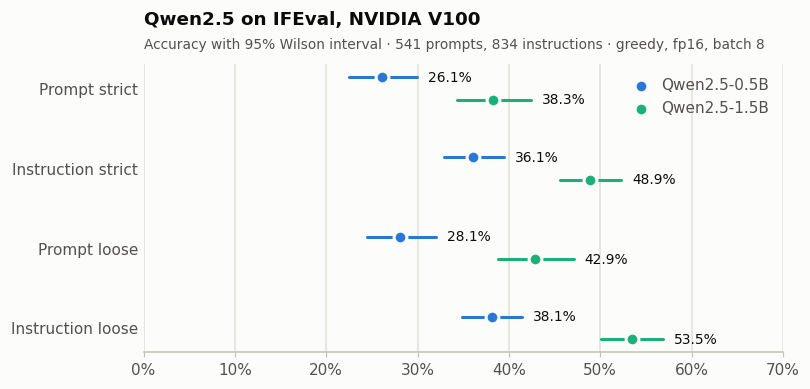

| Metric | 0.5B | 0.5B 95% CI | 1.5B | 1.5B 95% CI |
|---|---|---|---|---|
| Prompt strict | 26.1% | 22.5–29.9 | 38.3% | 34.3–42.4 |
| Instruction strict | 36.1% | 32.9–39.4 | 48.9% | 45.5–52.3 |
| Prompt loose | 28.1% | 24.5–32.0 | 42.9% | 38.8–47.1 |
| Instruction loose | 38.1% | 34.9–41.5 | 53.5% | 50.1–56.8 |

In [5]:
base = four_metrics(BASELINE)
big = four_metrics(SCALE)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for y, name in enumerate(reversed(METRICS)):
    for offset, metrics, colour in [(0.14, base, QWEN), (-0.14, big, QWEN15)]:
        k, n = metrics[name]
        lo, hi = wilson(k, n)
        ax.plot([100 * lo, 100 * hi], [y + offset] * 2, color=colour, lw=2,
                solid_capstyle="round", zorder=2)
        ax.scatter([100 * k / n], [y + offset], color=colour, **DOT,
                   label=None if y else ("Qwen2.5-0.5B" if colour == QWEN else "Qwen2.5-1.5B"))
        ax.text(100 * hi + 1.2, y + offset, f"{100 * k / n:.1f}%", va="center", fontsize=9)
ax.set_yticks(range(len(METRICS)), list(reversed(METRICS)))
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 70)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", labelcolor=INK_2, handletextpad=0.3)
title(ax, "Qwen2.5 on IFEval, NVIDIA V100",
      "Accuracy with 95% Wilson interval · 541 prompts, 834 instructions · greedy, fp16, batch 8")
save(fig, "01_headline_metrics")

table(["Metric", "0.5B", "0.5B 95% CI", "1.5B", "1.5B 95% CI"],
      [[x, pct(*base[x]), ci(*base[x]), pct(*big[x]), ci(*big[x])] for x in METRICS])

## 3. Comparison with published numbers

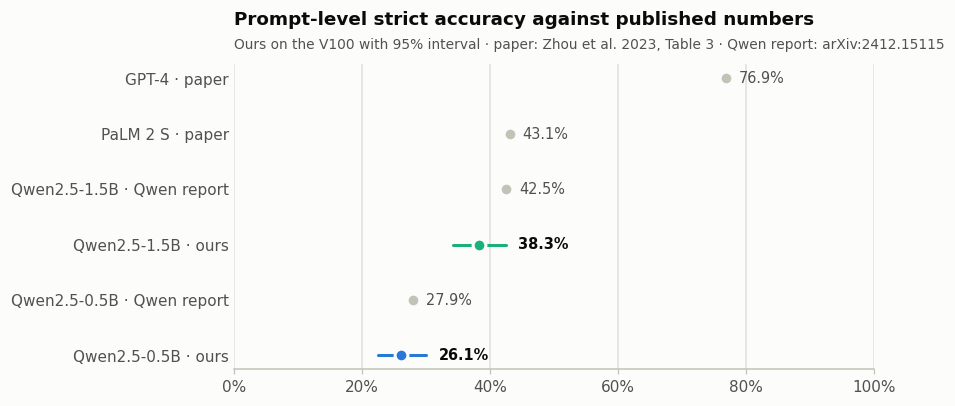

| Model | Prompt-level strict | Source |
|---|---|---|
| GPT-4 · paper | 76.9% | published |
| PaLM 2 S · paper | 43.1% | published |
| Qwen2.5-1.5B · Qwen report | 42.5% | published |
| Qwen2.5-1.5B · ours | 38.3% (34.3–42.4) | this harness, V100 |
| Qwen2.5-0.5B · Qwen report | 27.9% | published |
| Qwen2.5-0.5B · ours | 26.1% (22.5–29.9) | this harness, V100 |

In [6]:
models = [   # (label, prompt-level strict %, colour or None for published, (k, n) for ours)
    ("GPT-4 · paper", PAPER_TABLE3["GPT-4"]["Prompt strict"], None, None),
    ("PaLM 2 S · paper", PAPER_TABLE3["PaLM 2 S"]["Prompt strict"], None, None),
    ("Qwen2.5-1.5B · Qwen report", QWEN_REPORT["Qwen2.5-1.5B-Instruct"], None, None),
    ("Qwen2.5-1.5B · ours", None, QWEN15, big["Prompt strict"]),
    ("Qwen2.5-0.5B · Qwen report", QWEN_REPORT["Qwen2.5-0.5B-Instruct"], None, None),
    ("Qwen2.5-0.5B · ours", None, QWEN, base["Prompt strict"]),
]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for y, (label, value, colour, kn) in enumerate(reversed(models)):
    if kn:
        value = 100 * kn[0] / kn[1]
        lo, hi = wilson(*kn)
        ax.plot([100 * lo, 100 * hi], [y, y], color=colour, lw=2, solid_capstyle="round", zorder=2)
        right = 100 * hi
    else:
        right = value
    ax.scatter([value], [y], color=colour or CONTEXT, **DOT)
    ax.text(right + 2, y, f"{value:.1f}%", va="center", fontsize=9.5,
            color=INK if kn else INK_2, fontweight="semibold" if kn else "normal")
ax.set_yticks(range(len(models)), [m[0] for m in reversed(models)])
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
title(ax, "Prompt-level strict accuracy against published numbers",
      "Ours on the V100 with 95% interval · paper: Zhou et al. 2023, Table 3 · Qwen report: arXiv:2412.15115")
save(fig, "02_published_comparison")

rows = []
for label, value, colour, kn in models:
    if kn:
        rows.append([label, f"{100 * kn[0] / kn[1]:.1f}% ({ci(*kn)})", "this harness, V100"])
    else:
        rows.append([label, f"{value:.1f}%", "published"])
table(["Model", "Prompt-level strict", "Source"], rows)

## 4. Where the models fail

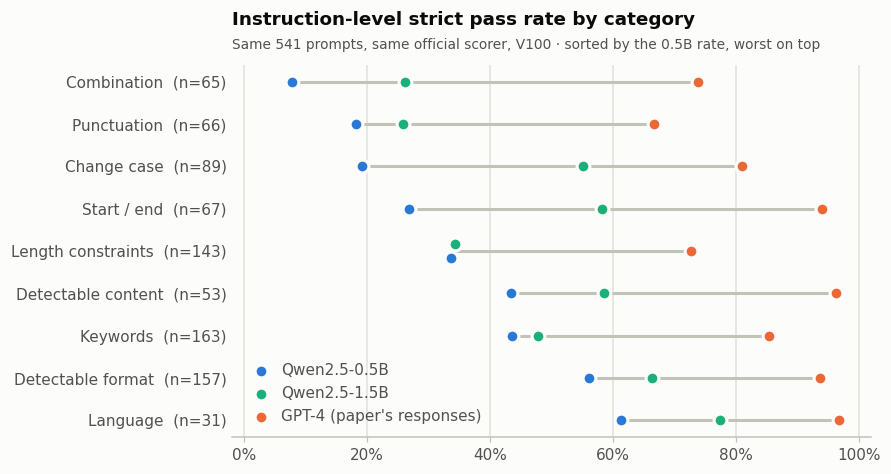

| Category | n | Qwen 0.5B | Qwen 1.5B | GPT-4 |
|---|---|---|---|---|
| Combination | 65 | 7.7% | 26.2% | 73.8% |
| Punctuation | 66 | 18.2% | 25.8% | 66.7% |
| Change case | 89 | 19.1% | 55.1% | 80.9% |
| Start / end | 67 | 26.9% | 58.2% | 94.0% |
| Length constraints | 143 | 33.6% | 34.3% | 72.7% |
| Detectable content | 53 | 43.4% | 58.5% | 96.2% |
| Keywords | 163 | 43.6% | 47.9% | 85.3% |
| Detectable format | 157 | 56.1% | 66.2% | 93.6% |
| Language | 31 | 61.3% | 77.4% | 96.8% |

In [7]:
CATEGORY_NAMES = {
    "change_case": "Change case", "combination": "Combination", "detectable_content": "Detectable content",
    "detectable_format": "Detectable format", "keywords": "Keywords", "language": "Language",
    "length_constraints": "Length constraints", "punctuation": "Punctuation", "startend": "Start / end",
}


def dumbbell(series, labels, heading, sub, name, height):
    """One row per group, one dot per series, joined by a hairline.
    Sorted by the first series' rate, worst on top."""
    first = series[0][1]
    order = sorted(first, key=lambda g: (first[g][0] / first[g][1], g), reverse=True)
    fig, ax = plt.subplots(figsize=(7.5, height))
    for y, g in enumerate(order):
        values = [100 * s[1][g][0] / s[1][g][1] for s in series]
        ax.plot([min(values), max(values)], [y, y], color=AXIS, lw=2, zorder=1)
        # Equal rates would stack one dot exactly on another and hide it, so
        # dots within 1.5 points of each other are spread apart vertically,
        # symmetrically about the row, by roughly one dot's width.
        for i, ((label, _, colour), v) in enumerate(zip(series, values)):
            group = [j for j, w in enumerate(values) if abs(w - v) < 1.5]
            off = (group.index(i) - (len(group) - 1) / 2) * 0.34 if len(group) > 1 else 0.0
            ax.scatter([v], [y + off], color=colour, label=label if y == 0 else None, **DOT)
    ax.set_yticks(range(len(order)), [labels(g) for g in order])
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(-2, 102)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower left", handletextpad=0.3, labelcolor=INK_2)
    title(ax, heading, sub)
    save(fig, name)
    return order


by_category = lambda iid: iid.split(":")[0]
q_cat, s_cat, g_cat = rates_by(BASELINE, by_category), rates_by(SCALE, by_category), rates_by(REF, by_category)
order = dumbbell([("Qwen2.5-0.5B", q_cat, QWEN), ("Qwen2.5-1.5B", s_cat, QWEN15),
                  ("GPT-4 (paper's responses)", g_cat, GPT4)],
                 lambda g: f"{CATEGORY_NAMES[g]}  (n={q_cat[g][1]})",
                 "Instruction-level strict pass rate by category",
                 "Same 541 prompts, same official scorer, V100 · sorted by the 0.5B rate, worst on top",
                 "03_by_category", 4.4)
table(["Category", "n", "Qwen 0.5B", "Qwen 1.5B", "GPT-4"],
      [[CATEGORY_NAMES[g], q_cat[g][1], pct(*q_cat[g]), pct(*s_cat[g]), pct(*g_cat[g])]
       for g in reversed(order)])

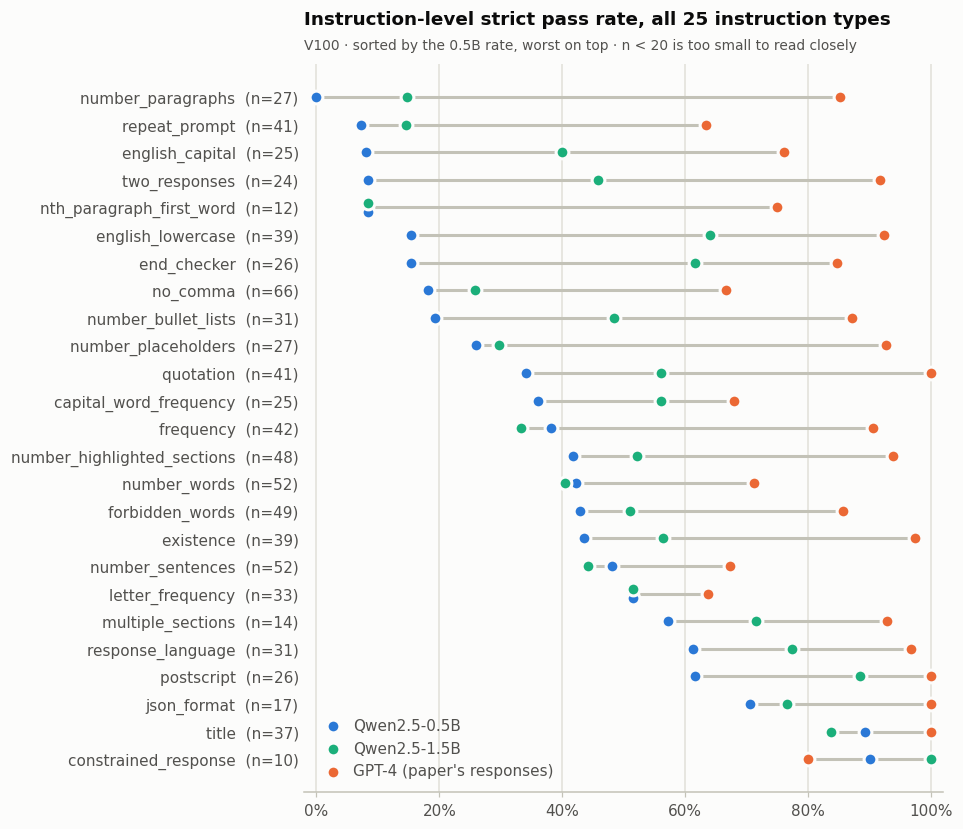

| Instruction type | n | Qwen 0.5B | Qwen 1.5B | GPT-4 |
|---|---|---|---|---|
| `length_constraints:number_paragraphs` | 27 | 0.0% (0/27) | 14.8% | 85.2% |
| `combination:repeat_prompt` | 41 | 7.3% (3/41) | 14.6% | 63.4% |
| `change_case:english_capital` | 25 | 8.0% (2/25) | 40.0% | 76.0% |
| `combination:two_responses` | 24 | 8.3% (2/24) | 45.8% | 91.7% |
| `length_constraints:nth_paragraph_first_word` | 12 | 8.3% (1/12) | 8.3% | 75.0% |
| `change_case:english_lowercase` | 39 | 15.4% (6/39) | 64.1% | 92.3% |
| `startend:end_checker` | 26 | 15.4% (4/26) | 61.5% | 84.6% |
| `punctuation:no_comma` | 66 | 18.2% (12/66) | 25.8% | 66.7% |
| `detectable_format:number_bullet_lists` | 31 | 19.4% (6/31) | 48.4% | 87.1% |
| `detectable_content:number_placeholders` | 27 | 25.9% (7/27) | 29.6% | 92.6% |
| `startend:quotation` | 41 | 34.1% (14/41) | 56.1% | 100.0% |
| `change_case:capital_word_frequency` | 25 | 36.0% (9/25) | 56.0% | 68.0% |
| `keywords:frequency` | 42 | 38.1% (16/42) | 33.3% | 90.5% |
| `detectable_format:number_highlighted_sections` | 48 | 41.7% (20/48) | 52.1% | 93.8% |
| `length_constraints:number_words` | 52 | 42.3% (22/52) | 40.4% | 71.2% |
| `keywords:forbidden_words` | 49 | 42.9% (21/49) | 51.0% | 85.7% |
| `keywords:existence` | 39 | 43.6% (17/39) | 56.4% | 97.4% |
| `length_constraints:number_sentences` | 52 | 48.1% (25/52) | 44.2% | 67.3% |
| `keywords:letter_frequency` | 33 | 51.5% (17/33) | 51.5% | 63.6% |
| `detectable_format:multiple_sections` | 14 | 57.1% (8/14) | 71.4% | 92.9% |
| `language:response_language` | 31 | 61.3% (19/31) | 77.4% | 96.8% |
| `detectable_content:postscript` | 26 | 61.5% (16/26) | 88.5% | 100.0% |
| `detectable_format:json_format` | 17 | 70.6% (12/17) | 76.5% | 100.0% |
| `detectable_format:title` | 37 | 89.2% (33/37) | 83.8% | 100.0% |
| `detectable_format:constrained_response` | 10 | 90.0% (9/10) | 100.0% | 80.0% |

In [8]:
q_type, s_type, g_type = rates_by(BASELINE, str), rates_by(SCALE, str), rates_by(REF, str)
order = dumbbell([("Qwen2.5-0.5B", q_type, QWEN), ("Qwen2.5-1.5B", s_type, QWEN15),
                  ("GPT-4 (paper's responses)", g_type, GPT4)],
                 lambda g: f"{g.split(':')[1]}  (n={q_type[g][1]})",
                 "Instruction-level strict pass rate, all 25 instruction types",
                 "V100 · sorted by the 0.5B rate, worst on top · n < 20 is too small to read closely",
                 "04_by_instruction_type", 8.6)
table(["Instruction type", "n", "Qwen 0.5B", "Qwen 1.5B", "GPT-4"],
      [[f"`{g}`", q_type[g][1], f"{pct(*q_type[g])} ({q_type[g][0]}/{q_type[g][1]})",
        pct(*s_type[g]), pct(*g_type[g])] for g in reversed(order)])

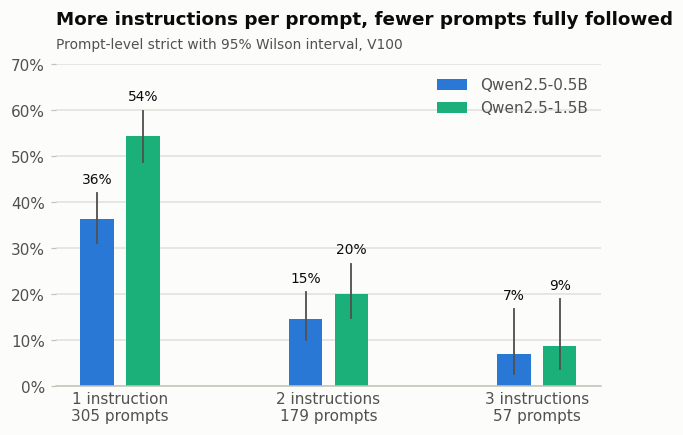

| Instructions in prompt | Prompts | 0.5B fully followed | 1.5B fully followed |
|---|---|---|---|
| 1 | 305 | 111 (36.4%) | 166 (54.4%) |
| 2 | 179 | 26 (14.5%) | 36 (20.1%) |
| 3 | 57 | 4 (7.0%) | 5 (8.8%) |

In [9]:
def by_instruction_count(run):
    out = collections.defaultdict(lambda: [0, 0])
    for r in read_jsonl(run / "eval_results_strict.jsonl"):
        out[len(r["instruction_id_list"])][0] += r["follow_all_instructions"]
        out[len(r["instruction_id_list"])][1] += 1
    return out


small, large = by_instruction_count(BASELINE), by_instruction_count(SCALE)
counts = sorted(small)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for offset, data, colour, label in [(-0.11, small, QWEN, "Qwen2.5-0.5B"), (0.11, large, QWEN15, "Qwen2.5-1.5B")]:
    for x in counts:
        k, n = data[x]
        lo, hi = wilson(k, n)
        ax.bar(x + offset, 100 * k / n, width=0.16, color=colour, zorder=2,
               label=label if x == counts[0] else None)
        ax.plot([x + offset] * 2, [100 * lo, 100 * hi], color=INK_2, lw=1.2, zorder=3)
        ax.text(x + offset, 100 * hi + 1.5, f"{100 * k / n:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(counts, [f"{x} instruction{'s' if x > 1 else ''}\n{small[x][1]} prompts" for x in counts])
ax.tick_params(axis="x", length=0)
ax.set_ylim(0, 70)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", labelcolor=INK_2)
title(ax, "More instructions per prompt, fewer prompts fully followed",
      "Prompt-level strict with 95% Wilson interval, V100")
save(fig, "05_by_instruction_count")

table(["Instructions in prompt", "Prompts", "0.5B fully followed", "1.5B fully followed"],
      [[x, small[x][1], f"{small[x][0]} ({pct(*small[x])})", f"{large[x][0]} ({pct(*large[x])})"]
       for x in counts])

## 5. Response length and truncation

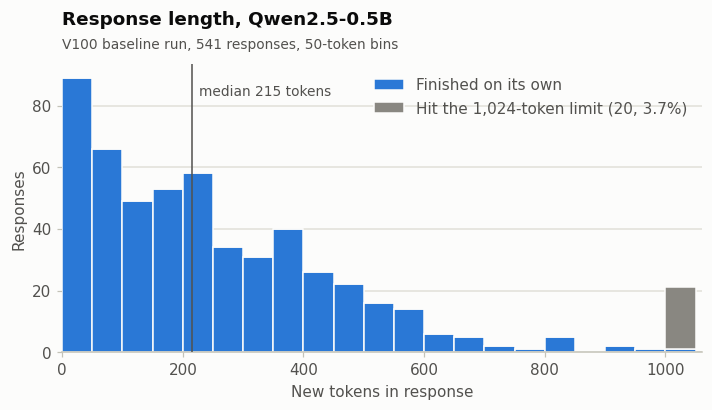

| Median | 90th percentile | Truncated | Truncated but still passed | Max gain if all truncated passed |
|---|---|---|---|---|
| 215 | 559 | 20 (3.7%) | 9 / 20 | +2.0 points |

In [10]:
gens = read_jsonl(BASELINE / "generations.jsonl")
complete = [g["n_new_tokens"] for g in gens if not g["truncated"]]
cut_off = [g["n_new_tokens"] for g in gens if g["truncated"]]
lengths = sorted(g["n_new_tokens"] for g in gens)
median = lengths[len(lengths) // 2]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist([complete, cut_off], bins=range(0, 1051, 50), stacked=True, color=[QWEN, MUTED],
        edgecolor=SURFACE, linewidth=1, zorder=2,
        label=["Finished on its own", f"Hit the 1,024-token limit ({len(cut_off)}, {pct(len(cut_off), len(gens))})"])
ax.axvline(median, color=INK_2, lw=1, zorder=3)
ax.text(median + 12, ax.get_ylim()[1] * 0.93, f"median {median} tokens", color=INK_2, fontsize=9, va="top")
ax.set_xlim(0, 1060)
ax.set_xlabel("New tokens in response")
ax.set_ylabel("Responses")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", labelcolor=INK_2)
title(ax, "Response length, Qwen2.5-0.5B", "V100 baseline run, 541 responses, 50-token bins")
save(fig, "06_response_length")

strict = prompt_pass(BASELINE)
truncated_pass = sum(1 for g in gens if g["truncated"] and strict[g["prompt"]])
table(["Median", "90th percentile", "Truncated", "Truncated but still passed", "Max gain if all truncated passed"],
      [[median, lengths[int(len(lengths) * 0.9)], f"{len(cut_off)} ({pct(len(cut_off), len(gens))})",
        f"{truncated_pass} / {len(cut_off)}", f"+{100 * (len(cut_off) - truncated_pass) / len(gens):.1f} points"]])

## 6. Sensitivity to the system prompt (V100)

Only `prompt.system_prompt` differs between these runs. *Gained* = failed in the
baseline, passed with the variant (prompt-level strict); *lost* = the reverse.
p is an exact McNemar test on those paired prompts. Three variants were tested, so a
Bonferroni-corrected threshold is 0.05 / 3 ≈ 0.017.

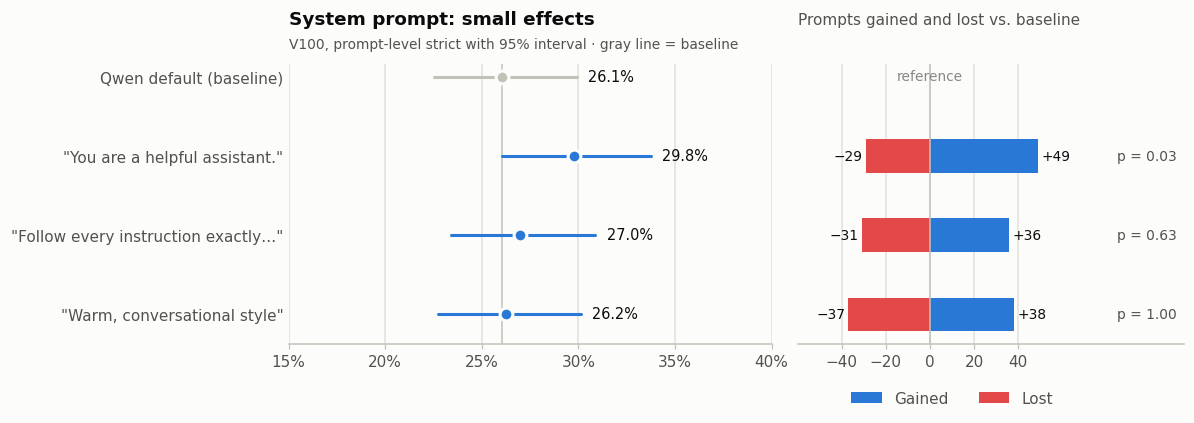

| System prompt | Prompt strict | Instruction strict | Prompt loose | Instruction loose | Truncated | Gained / lost | p |
|---|---|---|---|---|---|---|---|
| Qwen default (baseline) | 26.1% | 36.1% | 28.1% | 38.1% | 3.7% | — | — |
| "You are a helpful assistant." | 29.8% | 40.8% | 32.7% | 43.8% | 6.3% | +49 / −29 | 0.03 |
| "Follow every instruction exactly…" | 27.0% | 37.8% | 29.9% | 41.5% | 4.1% | +36 / −31 | 0.63 |
| "Warm, conversational style" | 26.2% | 36.1% | 29.0% | 39.1% | 4.8% | +38 / −37 | 1.00 |

In [11]:
results = []
for label, run in VARIANTS.items():
    gained, lost, p, same = paired(BASELINE, run) if run != BASELINE else (0, 0, 1.0, 541)
    results.append((label, run, four_metrics(run), gained, lost, p))

fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.3), sharey=True,
                                  gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.06})
base_rate = 100 * results[0][2]["Prompt strict"][0] / 541
left.axvline(base_rate, color=AXIS, lw=1, zorder=1)
for y, (label, run, m, gained, lost, p) in enumerate(reversed(results)):
    k, n = m["Prompt strict"]
    lo, hi = wilson(k, n)
    colour = CONTEXT if run == BASELINE else QWEN
    left.plot([100 * lo, 100 * hi], [y, y], color=colour, lw=2, solid_capstyle="round", zorder=2)
    left.scatter([100 * k / n], [y], color=colour, **DOT)
    left.text(100 * hi + 0.6, y, f"{100 * k / n:.1f}%", va="center", fontsize=9.5)
    if run == BASELINE:
        right.text(0, y, "reference", ha="center", va="center", color=MUTED, fontsize=9)
        continue
    right.barh(y, gained, height=0.42, color=GAINED, label="Gained" if y == 0 else None, zorder=2)
    right.barh(y, -lost, height=0.42, color=LOST, label="Lost" if y == 0 else None, zorder=2)
    right.text(gained + 1.5, y, f"+{gained}", va="center", fontsize=9)
    right.text(-lost - 1.5, y, f"−{lost}", va="center", ha="right", fontsize=9)
    right.text(112, y, f"p = {p:.2f}", va="center", ha="right", color=INK_2, fontsize=9)
left.set_yticks(range(len(results)), [r[0] for r in reversed(results)])
left.tick_params(axis="y", length=0)
left.set_xlim(15, 40)
left.xaxis.set_major_formatter(PercentFormatter(decimals=0))
left.grid(axis="y", visible=False)
title(left, "System prompt: small effects",
      "V100, prompt-level strict with 95% interval · gray line = baseline")
right.axvline(0, color=AXIS, lw=1)
right.set_xlim(-60, 115)
right.set_xticks([-40, -20, 0, 20, 40])
right.grid(axis="y", visible=False)
right.tick_params(axis="y", length=0)
right.set_title("Prompts gained and lost vs. baseline", fontsize=10, fontweight="normal", color=INK_2, pad=26)
right.legend(loc="upper center", bbox_to_anchor=(0.4, -0.12), ncol=2, labelcolor=INK_2)
save(fig, "07_system_prompt")

table(["System prompt", *METRICS, "Truncated", "Gained / lost", "p"],
      [[label, *(pct(*m[x]) for x in METRICS),
        pct(sum(g["truncated"] for g in read_jsonl(run / "generations.jsonl")), 541),
        "—" if run == BASELINE else f"+{gained} / −{lost}", "—" if run == BASELINE else f"{p:.2f}"]
       for label, run, m, gained, lost, p in results])

## 7. Laptop vs. V100

The same four configurations were run on the laptop (RTX 3050 Ti, batch 4, CUDA 12.1)
and on the V100 (batch 8, CUDA 11.8). GPU, batch size and CUDA runtime all changed
together, so this measures their combined effect.

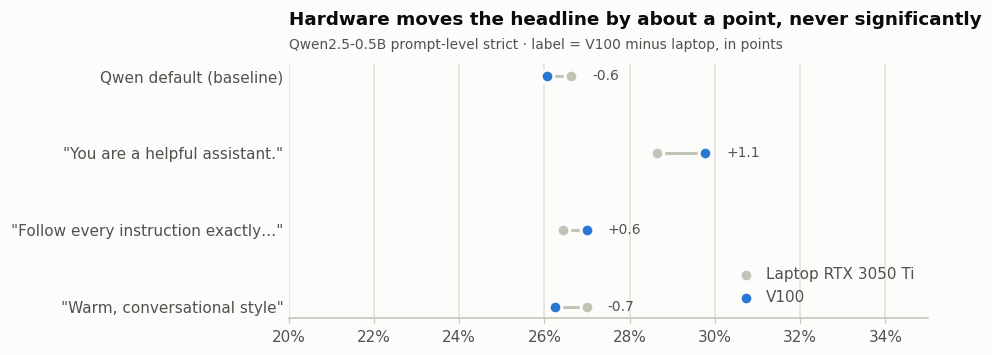

| Configuration | Laptop | V100 | Change (points) | Gained / lost | p | Identical responses |
|---|---|---|---|---|---|---|
| Qwen default (baseline) | 26.6% | 26.1% | -0.55 | +1 / −4 | 0.38 | 349 / 541 |
| "You are a helpful assistant." | 28.7% | 29.8% | +1.11 | +12 / −6 | 0.24 | 343 / 541 |
| "Follow every instruction exactly…" | 26.4% | 27.0% | +0.55 | +5 / −2 | 0.45 | 341 / 541 |
| "Warm, conversational style" | 27.0% | 26.2% | -0.74 | +2 / −6 | 0.29 | 340 / 541 |

In [12]:
rows, plot = [], []
for label in VARIANTS:
    lap, v100 = LAPTOP[label], VARIANTS[label]
    a, b = four_metrics(lap)["Prompt strict"], four_metrics(v100)["Prompt strict"]
    gained, lost, p, same = paired(lap, v100)
    plot.append((label, 100 * a[0] / a[1], 100 * b[0] / b[1]))
    rows.append([label, pct(*a), pct(*b), f"{100 * (b[0] - a[0]) / 541:+.2f}",
                 f"+{gained} / −{lost}", f"{p:.2f}", f"{same} / 541"])

fig, ax = plt.subplots(figsize=(7.5, 3.0))
for y, (label, lap, v100) in enumerate(reversed(plot)):
    ax.plot([lap, v100], [y, y], color=AXIS, lw=2, zorder=1)
    ax.scatter([lap], [y], color=CONTEXT, label="Laptop RTX 3050 Ti" if y == 0 else None, **DOT)
    ax.scatter([v100], [y], color=QWEN, label="V100" if y == 0 else None, **DOT)
    ax.text(max(lap, v100) + 0.5, y, f"{v100 - lap:+.1f}", va="center", fontsize=9, color=INK_2)
ax.set_yticks(range(len(plot)), [r[0] for r in reversed(plot)])
ax.tick_params(axis="y", length=0)
ax.set_xlim(20, 35)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", labelcolor=INK_2, handletextpad=0.3)
title(ax, "Hardware moves the headline by about a point, never significantly",
      "Qwen2.5-0.5B prompt-level strict · label = V100 minus laptop, in points")
save(fig, "08_laptop_vs_v100")

table(["Configuration", "Laptop", "V100", "Change (points)", "Gained / lost", "p", "Identical responses"], rows)

## 8. Scale: 0.5B → 1.5B (V100)

In [13]:
gained, lost, p, same = paired(BASELINE, SCALE)
table(["Metric", "Qwen2.5-0.5B", "Qwen2.5-1.5B", "Change (points)"],
      [[x, f"{pct(*base[x])} ({ci(*base[x])})", f"{pct(*big[x])} ({ci(*big[x])})",
        f"{100 * (big[x][0] / big[x][1] - base[x][0] / base[x][1]):+.1f}"] for x in METRICS])
print(f"Paired, prompt-level strict: +{gained} gained, −{lost} lost, exact McNemar p = {p:.2g}")
lengths15 = sorted(g["n_new_tokens"] for g in read_jsonl(SCALE / "generations.jsonl"))
print(f"1.5B: median {lengths15[len(lengths15) // 2]} tokens, "
      f"{sum(g['truncated'] for g in read_jsonl(SCALE / 'generations.jsonl'))} truncated")

| Metric | Qwen2.5-0.5B | Qwen2.5-1.5B | Change (points) |
|---|---|---|---|
| Prompt strict | 26.1% (22.5–29.9) | 38.3% (34.3–42.4) | +12.2 |
| Instruction strict | 36.1% (32.9–39.4) | 48.9% (45.5–52.3) | +12.8 |
| Prompt loose | 28.1% (24.5–32.0) | 42.9% (38.8–47.1) | +14.8 |
| Instruction loose | 38.1% (34.9–41.5) | 53.5% (50.1–56.8) | +15.3 |

Paired, prompt-level strict: +105 gained, −39 lost, exact McNemar p = 3.5e-08
1.5B: median 198 tokens, 12 truncated


## Saved figures

All charts above are written to `report/figures/` at 200 dpi for slides.

In [14]:
for path in sorted(FIGURES.glob("*.png")):
    print(path.relative_to(ROOT))

report/figures/01_headline_metrics.png
report/figures/02_published_comparison.png
report/figures/03_by_category.png
report/figures/04_by_instruction_type.png
report/figures/05_by_instruction_count.png
report/figures/06_response_length.png
report/figures/07_system_prompt.png
report/figures/08_laptop_vs_v100.png
